# 2 · Many Trees: Forest And Boosting

<a href="https://colab.research.google.com/github/FH-Prevail/steyr_course/blob/main/notebooks/2_forest_and_boosting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Advanced Data Analysis Techniques · Session 4: Forecasting With Tree-Based Models · Sina Mirshahi, FH OÖ Steyr*


**Hands-on 2.** All eight products at once, with the history of each product as input, and two ways to combine many trees. You will

- turn each product's past sales into inputs: last week, the last four weeks, the same week last year,
- split time into three periods: learn (2023), choose (2024), test (2025),
- choose the main knob of each tree model on 2024,
- test a decision tree, a random forest and LightGBM once on 2025, against the benchmark and the regression of session 2,
- find out for which products the trees pay off, and for which a regression is enough.

Sections 1 to 6 are the core; section 7 is optional.


**How to work with this notebook**

1. In Colab choose **File, Save a copy in Drive**. Your copy keeps your changes; this original never changes.
2. Run the cells from the top with **Shift + Enter**, or all at once with **Runtime, Run all**.
3. Read the result under each cell before you go on. You do not need to write code from scratch.

| Label | Meaning |
|---|---|
| `# EDIT` | a setting you may change, then run the cell again |
| `# CHECK` | the result for the unchanged course data; after an EDIT the numbers change, and that is fine |
| **Ask an AI** | a prompt that writes the same code in Gemini, ChatGPT or Claude, and how to check its answer |
| **Your answer** | a few words of your own: double-click the cell, write, then Shift + Enter |

The data is synthetic: a drinks wholesaler in Upper Austria, built to look like real weekly sales. No company data is contained.

In [1]:
# Start here: run this cell first. It loads the course data (one small table) and sets up the charts.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = "https://raw.githubusercontent.com/FH-Prevail/steyr_course/main/data"   # the course data on GitHub
if Path("data/drinks_weekly.csv").exists():      # a copy next to the notebook (Google Drive or upload) is used first
    DATA = "data"
sales = pd.read_csv(f"{DATA}/drinks_weekly.csv", parse_dates=["week_start"])
sales["product"] = sales["product"].astype(object)   # plain text labels: the regression formula works with every pandas version

# one colour per method, the same as on the slides
COLOURS = {"Actual sales": "#262626", "Repeat last year": "#E66A1F", "Linear regression": "#1B9E5A",
           "Decision tree": "#7A5C00", "Random forest": "#D04F95", "LightGBM": "#0B5CAD"}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:,.1f}".format)
print("Ready:", len(sales), "rows,", sales["product"].nunique(), "products, weeks from",
      sales["week_start"].min().date(), "to", sales["week_start"].max().date())
# CHECK: Ready: 1672 rows, 8 products, weeks from 2022-01-03 to 2025-12-29

Ready: 1672 rows, 8 products, weeks from 2022-01-03 to 2025-12-29


> **Ask an AI · the context first.** In ChatGPT or Claude, paste this before any prompt of this notebook (Gemini in Colab already sees the notebook):
>
> *"I work in Google Colab with pandas, scikit-learn, statsmodels and LightGBM. My table `sales` has one row per product and week: `week_start` (the Monday), `product` (8 drinks), `units` (cases sold, the target), `pallets` (pallets picked in the warehouse, known only after the week), `temp_forecast` (the weather forecast for the week, mean daily maximum in °C), `temp_actual` (the weather that came, known only after the week), `discount_pct` (the planned promotion discount, 0 = none) and `holiday_days` (public holidays from Monday to Friday). We plan on Sunday evening for the coming week. Keep the code short and commented, and never use information that is unknown on that Sunday."*
>
> **Check every answer:** run it, compare with the `# CHECK` line, and make sure you can say what each line does. Share only course data with an AI tool, never company data.

## 1. Inputs from the history

A tree cannot look back in time by itself. We give each week three numbers from the past, each computed **per product**:

- `last_week`: the sales one row, and here one week, back,
- `avg_last_4`: the average of the four weeks before,
- `same_week_last_year`: the sales 52 weeks back.

`shift(1)` moves every value one row down, so each week sees the row before it. That is the previous **week** only because our table has every week exactly once, sorted by date within each product; check this in your own data. `shift(-1)` would move next week's sales in: information from the future, called **leakage**. Then `week_of_year` (1 to 52 in our years) from the calendar.

In [2]:
sales = sales.sort_values(["product", "week_start"]).reset_index(drop=True)
for product, part in sales.groupby("product"):                                  # every Monday once, no gaps
    expected = pd.date_range(part["week_start"].min(), part["week_start"].max(), freq="W-MON")
    assert len(part) == len(expected) and (part["week_start"].to_numpy() == expected.to_numpy()).all(), product
by_product = sales.groupby("product")["units"]
sales["last_week"] = by_product.shift(1)                                         # one week back
sales["avg_last_4"] = by_product.transform(lambda s: s.shift(1).rolling(4).mean())   # the 4 weeks before
sales["same_week_last_year"] = by_product.shift(52)                             # 52 weeks back
sales["week_of_year"] = sales["week_start"].dt.isocalendar().week.astype(int)

sales[sales["product"] == "Ice tea"][["week_start", "units", "last_week", "avg_last_4", "same_week_last_year"]].iloc[60:66]
# CHECK: in every row, last_week is the units of the row above

,week_start,units,last_week,avg_last_4,same_week_last_year
478,2023-02-27,520,237.0,214.8,221.0
479,2023-03-06,226,520.0,298.0,388.0
480,2023-03-13,219,226.0,296.8,233.0
481,2023-03-20,182,219.0,300.5,238.0
482,2023-03-27,222,182.0,286.8,291.0
483,2023-04-03,195,222.0,212.2,336.0


**The inputs we use**, all known on Sunday evening: which product, the week of the year, the temperature forecast, the planned discount, the holidays, and the three history numbers. We leave out `pallets` and `temp_actual`: both are known only after the week.

## 2. Three periods: learn, choose, test

In session 2 the rows were companies, and a random 80/20 split was right. Here the rows are **weeks**: a random split would let the model learn from July 2025 to forecast June 2025, which no planner can do. So we split by time, into three periods:

- **2023**, to learn while we choose the knobs, and **2024**, to choose them (the validation year),
- **2023 and 2024** together, to learn the final models,
- **2025**, the final test, used once.

2022 only feeds the history numbers. **How we forecast:** the final models are trained once, on Sunday 5 January 2025, and then stay fixed. Every Sunday evening of 2025 they forecast the coming week, with that week's weather forecast and plan and the sales up to the week just finished. So the history inputs of a 2025 week use earlier 2025 sales: that is allowed, because they are known by then.

The comparisons on 2025 are planned now, before anything is tested: the benchmark, the regression of session 2, three tree models, and a regression per product. The trees need numbers, so `encode` turns the product into eight 0/1 columns, one per product.

> **Ask an AI** · *"Using `sales` after the history columns have been created, keep the rows with a complete history (drop rows without same_week_last_year). Use only product, week_of_year, temp_forecast, discount_pct, holiday_days, last_week, avg_last_4 and same_week_last_year as inputs; units is the target. Make four tables by date: learn_2023 and check_2024 for choosing settings, train (2023 and 2024) and test (2025). One-hot encode product with the same columns in every table. Print the shapes and the date ranges, and check that train ends before test begins."*
> **Check:** no random `train_test_split`; the shapes and dates must match the `# CHECK` line.

In [3]:
FEATURES = ["product", "week_of_year", "temp_forecast", "discount_pct", "holiday_days",
            "last_week", "avg_last_4", "same_week_last_year"]
PRODUCTS = sorted(sales["product"].unique())
COLUMNS = FEATURES[1:] + ["product_" + p.replace(" ", "_") for p in PRODUCTS]


def encode(table):
    """The model inputs as numbers: the inputs above, plus one 0/1 column per product."""
    X = pd.get_dummies(table[FEATURES], columns=["product"], dtype=int)
    X.columns = [c.replace(" ", "_") for c in X.columns]
    return X.reindex(columns=COLUMNS, fill_value=0)


data = sales.dropna(subset=["same_week_last_year"])               # 2022 only feeds the history numbers
year = data["week_start"].dt.year
learn_2023, check_2024 = data[year == 2023], data[year == 2024]   # to choose the knobs
train, test = data[year <= 2024], data[year == 2025].copy()       # the final models, and the final test
X_train, y_train = encode(train), train["units"]
X_test, y_test = encode(test), test["units"]
print("learn:", len(learn_2023), "rows | choose:", len(check_2024), "rows | train:", X_train.shape, "| test:", X_test.shape)
print("train weeks:", train["week_start"].min().date(), "to", train["week_start"].max().date())
print("test weeks: ", test["week_start"].min().date(), "to", test["week_start"].max().date())
# CHECK: learn: 416 rows | choose: 424 rows | train: (840, 15) | test: (416, 15)

learn: 416 rows | choose: 424 rows | train: (840, 15) | test: (416, 15)
train weeks: 2023-01-02 to 2024-12-30
test weeks:  2025-01-06 to 2025-12-29


In [4]:
def score(actual, forecast):
    """Three numbers for a forecast. MAE: the average miss in cases. WAPE: all misses added up, as a
    percentage of all cases sold. Bias: forecast minus actual, on average (minus means too low)."""
    if isinstance(actual, pd.Series) and isinstance(forecast, pd.Series):
        assert actual.index.equals(forecast.index), "Actuals and forecasts must belong to the same weeks."
    a, f = np.asarray(actual, dtype=float), np.asarray(forecast, dtype=float)
    assert a.ndim == 1 and a.size > 0 and a.shape == f.shape, "One forecast for every week, in one column."
    assert np.isfinite(a).all() and np.isfinite(f).all(), "Every week needs a number: no missing actual or forecast."
    miss, total = f - a, np.abs(a).sum()
    return pd.Series({"MAE, cases": np.abs(miss).mean(),
                      "WAPE, %": np.abs(miss).sum() / total * 100 if total else np.nan,   # undefined if nothing was sold
                      "Bias, cases": miss.mean()})

## 3. The benchmark and the straight line

The benchmark repeats last year: the sales 52 weeks earlier. The regression is the multiple regression of session 2 with all the inputs above; `C(product)` gives each product its own level, as `C(sector)` did for the sectors. It has no knobs to choose, so it learns from 2023 and 2024 directly. Their results on 2025 come in section 5, together with the trees, once every choice is made.

In [5]:
import statsmodels.formula.api as smf

test["Repeat last year"] = test["same_week_last_year"]
reg = smf.ols("units ~ C(product) + week_of_year + temp_forecast + discount_pct + holiday_days"
              " + last_week + avg_last_4 + same_week_last_year", data=train).fit()
test["Linear regression"] = reg.predict(test)
print("The regression learned from", len(train), "rows; its result on 2025 comes in section 5.")
# CHECK: The regression learned from 840 rows

The regression learned from 840 rows; its result on 2025 comes in section 5.


## 4. Three tree models, and their knobs chosen on 2024

- **Decision tree**: one tree, as in notebook 1, now for all products. Its main knob: `max_depth`.
- **Random forest**: 300 trees. Each tree learns from a random sample of the weeks, drawn with replacement (some weeks twice, some not at all), and at every question it may look at only a share of the inputs (`max_features`). The forest forecasts the **average** of its trees.
- **LightGBM**: boosting. The trees are built one after the other; each new tree learns what the trees before it still get wrong, and a small part of that correction (`learning_rate=0.05`) is added. Its main size knob: `num_leaves`.

All three learn from all eight products at once (global mode): what a promotion does to ice tea helps the model with radler.

**The rule:** for each model, try three values of its main knob, learn from 2023, score on 2024, and keep the value with the lowest error. 2025 stays untouched. (If Colab ever reports `ModuleNotFoundError: lightgbm`, run `!pip install lightgbm` in a new cell, then this cell again.)

> **Ask an AI** · *"For a scikit-learn DecisionTreeRegressor (max_depth 4, 6, 8, min_samples_leaf=5), a RandomForestRegressor (n_estimators=300, max_features 0.33, 0.5, 1.0) and a LightGBM LGBMRegressor (n_estimators=400, learning_rate=0.05, min_child_samples=10, num_leaves 7, 15, 31), all with random_state=42: fit each candidate on encode(learn_2023), compute the WAPE on encode(check_2024), and keep the value with the lowest WAPE per model. Never use test."*
> **Check:** the chosen values must match the `# CHECK` line.

In [6]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor


def wape_on_2024(model):
    """Learn from 2023 and return the WAPE on 2024: the number we choose a knob by."""
    model.fit(encode(learn_2023), learn_2023["units"])
    return score(check_2024["units"], model.predict(encode(check_2024)))["WAPE, %"]


candidates = {                                                     # EDIT: try other values
    "Decision tree, max_depth": {d: DecisionTreeRegressor(max_depth=d, min_samples_leaf=5, random_state=42) for d in (4, 6, 8)},
    "Random forest, max_features": {m: RandomForestRegressor(n_estimators=300, max_features=m, random_state=42, n_jobs=-1)
                                    for m in (0.33, 0.5, 1.0)},
    "LightGBM, num_leaves": {n: LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=n, min_child_samples=10,
                                              random_state=42, verbose=-1) for n in (7, 15, 31)},
}
chosen, valid_errors = {}, {}
for knob, models in candidates.items():
    errors = valid_errors[knob] = {value: wape_on_2024(model) for value, model in models.items()}
    chosen[knob] = min(errors, key=errors.get)
    print(f"{knob:28s}", "   ".join(f"{value}: {e:.1f} %" for value, e in errors.items()), f"  -> chosen: {chosen[knob]}")
# CHECK: chosen: max_depth 8, max_features 0.33, num_leaves 7

Decision tree, max_depth     4: 23.8 %   6: 22.9 %   8: 22.7 %   -> chosen: 8


Random forest, max_features  0.33: 16.5 %   0.5: 17.0 %   1.0: 18.4 %   -> chosen: 0.33


LightGBM, num_leaves         7: 16.9 %   15: 17.1 %   31: 17.4 %   -> chosen: 7


**What to see.** The differences on 2024 are small, often below one percentage point: the knobs matter less than the inputs. One validation year is also a small sample, so do not read much into a few tenths. What matters is the habit: **every choice is made on 2024, never on 2025.**

## 5. The final test on 2025

The three models learn again, from 2023 and 2024, with the chosen knobs, and forecast every week of 2025, once.

In [7]:
tree = DecisionTreeRegressor(max_depth=chosen["Decision tree, max_depth"], min_samples_leaf=5, random_state=42)
forest = RandomForestRegressor(n_estimators=300, max_features=chosen["Random forest, max_features"], random_state=42, n_jobs=-1)
boost = LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=chosen["LightGBM, num_leaves"], min_child_samples=10,
                      random_state=42, verbose=-1)
for name, model in [("Decision tree", tree), ("Random forest", forest), ("LightGBM", boost)]:
    model.fit(X_train, y_train)                      # learn again, from 2023 and 2024
    test[name] = model.predict(X_test)               # forecast every week of 2025

METHODS = ["Repeat last year", "Linear regression", "Decision tree", "Random forest", "LightGBM"]
results = pd.DataFrame({m: score(test["units"], test[m]) for m in METHODS}).T
results["WAPE on 2023-24 (learned from), %"] = [np.nan, score(y_train, reg.predict(train))["WAPE, %"],
                                                *[score(y_train, m.predict(X_train))["WAPE, %"] for m in (tree, forest, boost)]]
results
# CHECK: WAPE on 2025: 29.1, 21.0, 21.1, 16.1, 14.8 %

,"MAE, cases","WAPE, %","Bias, cases","WAPE on 2023-24 (learned from), %"
Repeat last year,266.2,29.1,-34.7,NaN
Linear regression,192.1,21.0,-9.0,20.9
Decision tree,192.7,21.1,-36.0,12.2
Random forest,147.5,16.1,-28.9,5.3
LightGBM,135.4,14.8,-8.7,7.4


**What to see.** On 2025, LightGBM's misses add up to 14.8 % of all cases sold, the random forest's to 16.1 %, the regression's to 21.0 % and repeating last year to 29.1 %. In our data, one tree is about as good as the regression, and many trees together are clearly better.

The last column is the error on the weeks the models learned from. The forest and LightGBM are much better there than on 2025: they know those weeks. That is why only the test year counts.

## 6. Which products gain?

The same comparison, product by product (WAPE, %):

In [8]:
def wape_by_product(table, methods):
    """The WAPE of every method, product by product, with the same score function as above."""
    rows = {product: {m: score(part["units"], part[m])["WAPE, %"] for m in methods}
            for product, part in table.groupby("product")}
    return pd.DataFrame(rows).T


by_product = wape_by_product(test, METHODS)
by_product.round(1)
# CHECK: Ice tea: 31.7 % with the regression, 25.6 % with LightGBM

,Repeat last year,Linear regression,Decision tree,Random forest,LightGBM
Apple spritzer,27.3,18.2,19.6,14.6,11.3
Energy drink,39.1,27.7,28.7,16.0,16.5
Ice tea,49.2,31.7,34.1,22.9,25.6
Lager beer,24.6,14.7,15.3,14.3,11.2
Mineral water,25.7,15.6,18.6,16.1,13.4
Mulled wine,17.1,92.1,43.7,20.0,36.2
Orange juice,13.9,26.5,18.7,8.8,12.1
Radler,47.8,28.8,27.0,23.0,21.6


**What to see.** The trees gain most where the weather and the promotions drive the sales: ice tea, radler, apple spritzer. Two products stand out. Mulled wine follows the calendar, and the models have seen only two Advent seasons: repeating last year is best in our data. Orange juice hardly reacts to the weather, yet the regression misses 26.5 % of its cases. Why?

The regression of all products gives **every product the same slopes**: one degree warmer adds the same number of cases of orange juice as of ice tea. A fairer test gives each product a regression of its own:

In [9]:
local = []
for product, part in data.groupby("product"):                         # one regression per product
    own = smf.ols("units ~ week_of_year + temp_forecast + discount_pct + holiday_days"
                  " + last_week + avg_last_4 + same_week_last_year",
                  data=part[part["week_start"].dt.year <= 2024]).fit()
    local.append(own.predict(part[part["week_start"].dt.year == 2025]))
test["Regression per product"] = pd.concat(local)                       # lines up with the test rows by their index

side = ["Linear regression", "Regression per product", "Random forest", "LightGBM"]
per_product = wape_by_product(test, side)
per_product.loc["All products"] = [score(test["units"], test[m])["WAPE, %"] for m in side]
per_product.round(1)
# CHECK: Orange juice: 7.2 % with its own regression; Radler: 27.0 % against 21.6 % with LightGBM

,Linear regression,Regression per product,Random forest,LightGBM
Apple spritzer,18.2,16.8,14.6,11.3
Energy drink,27.7,15.0,16.0,16.5
Ice tea,31.7,32.6,22.9,25.6
Lager beer,14.7,13.5,14.3,11.2
Mineral water,15.6,14.6,16.1,13.4
Mulled wine,92.1,41.5,20.0,36.2
Orange juice,26.5,7.2,8.8,12.1
Radler,28.8,27.0,23.0,21.6
All products,21.0,17.0,16.1,14.8


**What to see.** With a regression of its own, orange juice's misses add up to only 7.2 % of its cases sold, less than with either tree model: in this test, for this product, the straight line forecasts best (which does not prove that the business relationship is a straight line). For ice tea and radler, whose sales bend with the temperature, the trees stay clearly ahead (32.6 % against 22.9 % for ice tea; 27.0 % against 21.6 % for radler). Over all products the regressions per product reach 17.0 %, LightGBM 14.8 %.

A regression could also follow curves and interactions, if you write them into the formula; a tree finds them by itself. This test shows which of the tested models forecast 2025 better, not the true shape of the business relationship. These product winners describe 2025; choosing a separate model for each product from this table would need yet another untouched year to test that choice. **The practical rule:** compare a regression and a tree on a validation year, choose there, and report the chosen one on the test year, against a benchmark.

## 7. OPTIONAL: look at one product

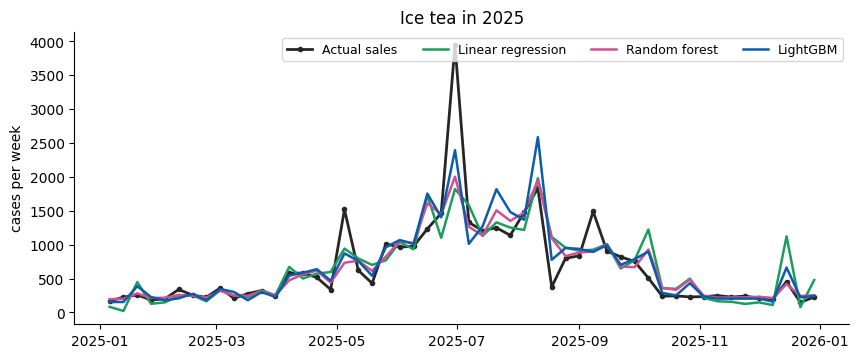

MAE, cases    172.5
WAPE, %        25.6
Bias, cases    16.2
dtype: float64

In [10]:
product = "Ice tea"            # EDIT: any of the eight products
show = ["Linear regression", "Random forest", "LightGBM"]

one = test[test["product"] == product]
assert len(one), f"No product called {product!r}; choose one of {PRODUCTS}"
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(one["week_start"], one["units"], color=COLOURS["Actual sales"], lw=2, marker="o", ms=3, label="Actual sales")
for m in show:
    ax.plot(one["week_start"], one[m], color=COLOURS[m], lw=1.8, label=m)
ax.set(title=f"{product} in 2025", ylabel="cases per week")
ax.legend(ncol=4, fontsize=9)
plt.show()
score(one["units"], one["LightGBM"]).round(1)

**Try it.** Change `product` to Radler, Energy drink and Mulled wine. Where does LightGBM follow the actual sales, and where not? Look at the week of 30 June 2025, the hottest of all: we come back to it in notebook 3.

**Try more knobs** (optional): in section 4, add other values, for example `n_estimators` of the forest or `min_child_samples` of LightGBM, run section 4 again, and see whether the choice on 2024 changes. Leave section 5 alone: once you have seen 2025, a new choice would need another untouched year to be tested fairly.

### Your answer (not graded; it prepares your project)

1. Which method has the lowest WAPE on 2025, and how much lower is it than the regression? ___
2. Name one product where the trees gain a lot, and one where a regression is enough. Why the difference? ___
3. Why are the knobs chosen on 2024, and what would go wrong if you chose them on 2025? ___

**Next:** in notebook 3 we check a forecast that looks too good, find what a tree cannot do, and ask the model for its reasons.